# <span style='font-size:xx-large'>Numerical Simulation of Planetary orbits: Numerical Accuracy, Orbital Classification and Precession



## 1. Introduction

Planetary motion is one of the many classical applications of Newtonian mechanics. For a planet of negligible mass orbiting a much more massive star, the motion can be approximated as a two-body problem in which the star remains fixed with the planet moving under the influence of its gravitational field. Although some orbital properties can be obtained analytically, numerical methods provide a flexible way of solving the equations of motion and investigating how the trajectory depends on the initial conditions and the form of the gravitational force.

The aim of this project is to develop a numerical simulation of a single planet orbiting a fixed star and to investigate both the numerical and physical behaviour of the system. To tackle this project two numerical integration methods are used, the Euler method and the fourth-order Runge-Kutta method (RK4). These methods are compared by examining how accurately they reproduce a circular orbit and how well they conserve quantities such as orbital radius and total mechanical energy. Their numerical convergence is also investigated by varying the timestep.

After determining which numerical method provides the more accurate solution, the chosen simulation method is then used to study the effect of changing the planet's initial velocity. Different initial conditions are used to generate circular, elliptical, parabolic and hyperbolic trajectories. The resulting orbits are classified using their specific orbital energy and eccentricity, and a range of bound orbits with different eccentricities is explored.

Finally, the gravitational force law is modified slightly from the Newtonian inverse-square form. A force proportional to $r^{-(2+\delta)}$, where $\delta$ is a small parameter, is used to investigate how even a small deviation from the inverse-square law causes the orientation of an elliptical orbit to change over time. The resulting apsidal precession is measured numerically and its dependence on $\delta$ is explored.

The project combines numerical-method testing with an investigation of several features of orbital mechanics. The main questions are how accurately the two numerical methods reproduce planetary motion, how the trajectory changes with the initial conditions, and how a small modification to the force law affects an elliptical orbit over time.



## 2. Physical and Mathematical Background
The system considered in this project consists of a single planet moving in two dimensions under the gravitational attraction of a much more massive star. The star is assumed to remain fixed at the origin, while the mass of the planet is taken to be negligible in comparison. This allows the motion of the planet to be described using Newtonian gravity without considering the motion of the star [1].

The gravitational force acting on a planet of mass $m$ at a distance $r$ from a star of mass $M$ is

$$
F = \frac{GMm}{r^2},
$$

where $G$ is the gravitational constant. Dividing the force by the mass of the planet gives the magnitude of its acceleration,

$$
a = \frac{GM}{r^2}.
$$

It is convenient to define the gravitational parameter

$$
\mu = GM.
$$

For the Sun, when distance is measured in astronomical units (AU) and time in years,

$$
\mu = 4\pi^2 \; \mathrm{AU^3\,yr^{-2}}.
$$

The position of the planet is represented by the Cartesian coordinates $(x,y)$, with its distance from the star given by

$$
r = \sqrt{x^2+y^2}.
$$

Since gravity always acts towards the star, the acceleration vector is

$$
\mathbf{a} = -\frac{\mu}{r^3}\mathbf{r}.
$$

The corresponding Cartesian components of acceleration are therefore

$$
a_x = -\frac{\mu x}{r^3},
\qquad
a_y = -\frac{\mu y}{r^3}.
$$

To solve the motion numerically, the second-order equations are written as four first-order differential equations,

$$
\frac{dx}{dt}=v_x,
\qquad
\frac{dy}{dt}=v_y,
$$

$$
\frac{dv_x}{dt}=-\frac{\mu x}{r^3},
\qquad
\frac{dv_y}{dt}=-\frac{\mu y}{r^3}.
$$

The state of the planet can therefore be represented by the vector

$$
\mathbf{S} = [x,y,v_x,v_y].
$$

For an initially circular orbit of radius $r$, the required orbital speed is obtained by equating the gravitational acceleration with the centripetal acceleration. This gives [1]

$$
v_{\mathrm{circular}} = \sqrt{\frac{\mu}{r}}.
$$

The specific orbital energy is also useful for determining the type of orbit produced,

$$
\epsilon = \frac{v^2}{2}-\frac{\mu}{r}.
$$

A negative specific orbital energy corresponds to a bound orbit, zero energy corresponds to the parabolic escape case, and positive energy corresponds to a hyperbolic trajectory [1].

The eccentricity provides another way of describing the shape of an orbit. Using the specific angular momentum $h$, the eccentricity is calculated as

$$
e = \sqrt{1+\frac{2\epsilon h^2}{\mu^2}},
$$

where in two dimensions the specific angular momentum is

$$
h=xv_y-yv_x.
$$

For a circular orbit $e=0$, an elliptical orbit has $0<e<1$, a parabolic trajectory has $e=1$, and a hyperbolic trajectory has $e>1$ [1].

## 3. Numerical Methods

The equations of motion described in the previous section form a system of first-order ordinary differential equations. These equations are then solved numerically by advancing the state vector of the planet through a sequence of discrete timesteps of size $\Delta t$. 

Two numerical integration methods are considered: the Euler method and the fourth-order Runge-Kutta method (RK4). The Euler method is a simple first-order approximation, while RK4 uses several evaluations of the equations of motion within each timestep to obtain a higher-order approximation [2, 3]. The performance of the two methods is compared later by examining the resulting orbital trajectories, conservation of orbital quantities and numerical convergence.

### 3.1 Euler Method

The Euler method estimates the state of the system at the next timestep using the derivative evaluated at the beginning of the current timestep. If the state vector at timestep $n$ is $\mathbf{S}_n$, the Euler update is

$$
\mathbf{S}_{n+1}
=
\mathbf{S}_n
+
\Delta t\,f(t_n,\mathbf{S}_n),
$$

where $f(t_n,\mathbf{S}_n)$ represents the derivatives of the position and velocity obtained from the equations of motion.

The method is straightforward to implement, but because it is a first-order method its error decreases relatively slowly as the timestep is reduced [2, 3]. Here it is used as a simple reference method for comparison with RK4.

In [138]:
def euler_step(function, t, state, dt, mu):
    derivatives = function(t, state, mu)
    new_state = state + dt * derivatives
    return new_state

### 3.2 Fourth-Order Runge-Kutta Method 

The fourth-order Runge-Kutta method improves on the Euler method. This is done by evaluating the derivatives several times within each timestep. Instead of using only the slope at the beginning of the timestep, RK4 calculates four intermediate estimates, 

$$
k_1 = f(t_n,\mathbf{S}_n), 
$$ 

$$
k_2 = f\left(t_n+\frac{\Delta t}{2}, \mathbf{S}_n+\frac{\Delta t}{2}k_1\right), 
$$ 

$$
k_3 = f\left(t_n+\frac{\Delta t}{2}, \mathbf{S}_n+\frac{\Delta t}{2}k_2\right), 
$$ 

$$ k_4 = f\left(t_n+\Delta t, \mathbf{S}_n+\Delta t,k_3\right).
$$ 

These estimates are then combined to update the state vector according to 

$$
\mathbf{S}_{n+1} = \mathbf{S}_n + \frac{\Delta t}{6} \left( k_1+2k_2+2k_3+k_4 \right).
$$ 

Because RK4 is a fourth-order method, its numerical error decreases much more quickly with timestep than the first-order Euler method [2, 3]. This makes it better suited for accurately modelling orbital motion over many timesteps. 



In [139]:
def rk4_step(function, t, state, dt, mu):
    k1 = function(t, state, mu)
    k2 = function(t + dt / 2, state + dt * k1 / 2, mu)
    k3 = function(t + dt / 2, state + dt * k2 / 2, mu)
    k4 = function(t + dt, state + dt * k3, mu)

    new_state = state + (dt / 6) * (
        k1 + 2*k2 + 2*k3 + k4
    )

    return new_state

The orbit is evolved by repeatedly applying the chosen integration method to the state vector. The simulation begins from a specified initial position and velocity and advances in discrete timesteps of size $\Delta t$ until the required total simulation time is reached. 

At each timestep, the equations of motion are evaluated and the state vector 

$$
\mathbf{S} = [x,y,v_x,v_y]
$$ 

is updated using either the Euler or RK4 method. The resulting position and velocity at every timestep are stored so that the orbital trajectory and conserved quantities can be analysed afterwards. 

For the main simulations, the planet begins at a distance of $1$ AU from the star. The gravitational parameter is taken to be 

$$ 
\mu = 4\pi^2 ; \mathrm{AU^3,yr^{-2}}, 
$$ 

and a timestep of $\Delta t = 0.001$ years is used unless otherwise stated. This corresponds to approximately $0.365$ days. 



## 4. Implementation and initial conditions
The numerical model is implemented in Python using NumPy for numerical calculations and Matplotlib for plotting the resulting trajectories. The star is fixed at the origin and the planet is initially placed at a distance of $1$ AU along the positive $x$-axis.

The simulation uses astronomical units for distance and years for time. In these units the gravitational parameter of the Sun is

$$
\mu = 4\pi^2 \; \mathrm{AU^3\,yr^{-2}}.
$$

The initial position is chosen as

$$
x_0 = 1 \; \mathrm{AU}, \qquad y_0 = 0.
$$

For an initially circular orbit, the velocity must be perpendicular to the radius vector, with magnitude

$$
v_{\mathrm{circular}} = \sqrt{\frac{\mu}{r_0}}.
$$

Since the planet begins on the positive $x$-axis, the initial velocity is directed along the positive $y$-axis, giving

$$
v_{x,0}=0, \qquad v_{y,0}=v_{\mathrm{circular}}.
$$

In [140]:
import numpy as np
import matplotlib.pyplot as plt

# Gravitational parameter of the Sun in AU^3 yr^-2
mu = 4 * np.pi**2

# Initial position
x0 = 1.0
y0 = 0.0

# Initial distance from the Sun
r0 = np.sqrt(x0**2 + y0**2)

# Circular orbital speed
v_circular = np.sqrt(mu / r0)

# Initial velocity
vx0 = 0.0
vy0 = v_circular

# State vector [x, y, vx, vy]
initial_state = np.array([x0, y0, vx0, vy0], dtype=float)

The equations of motion are used by calculating the planet's distance from the origin and then using the gravitational acceleration components derived previously. At each evaluation, the current position and velocity are unpacked from the state vector and the corresponding acceleration towards the star is calculated. 

In [141]:
def equations_of_motion(t, state, mu):
    """
    Return the time derivatives for a planet orbiting a fixed star.
    """
    x, y, vx, vy = state

    r = np.sqrt(x**2 + y**2)

    if r == 0:
        raise ValueError(
            "The planet cannot be located at the centre of the star."
        )

    ax = -mu * x / r**3
    ay = -mu * y / r**3

    return np.array([vx, vy, ax, ay])

The simulation function repeatedly applies the selected numerical integration method until the required total time has been reached. The position and velocity at every timestep are stored in an array so that the resulting orbit and numerical accuracy can be analysed. 

In [142]:
def simulate_orbit_with_method(
    initial_state,
    total_time,
    dt,
    mu,
    step_method
):
    # This calcs the total number of integration steps
    number_of_steps = int(total_time / dt)

    # Creat arrays to store simulation times and state vectors    
    times = np.zeros(number_of_steps + 1)
    states = np.zeros((number_of_steps + 1, 4))

    states[0] = initial_state

    for i in range(number_of_steps):

        times[i + 1] = times[i] + dt

        states[i + 1] = step_method(
            function=equations_of_motion,
            t=times[i],
            state=states[i],
            dt=dt,
            mu=mu
        )

    return times, states

## 5. Numerical Validation and Comparison of Euler and RK4

Before investigating different orbital trajectories, the two integration methods are tested using a circular orbit. This is a useful validation case because the orbital radius and total mechanical energy should remain constant. 

The Euler and RK4 methods are therefore used to simulate the same initial circular orbit for one year using a timestep of $\Delta t = 0.001$ years. Their resulting trajectories, orbital radius and energy conservation are then compared. 

In [143]:
total_time = 1.0
dt = 0.001

# Euler simulation
times_euler, states_euler = simulate_orbit_with_method(
    initial_state=initial_state,
    total_time=total_time,
    dt=dt,
    mu=mu,
    step_method=euler_step
)

# RK4 simulation
times_rk4, states_rk4 = simulate_orbit_with_method(
    initial_state=initial_state,
    total_time=total_time,
    dt=dt,
    mu=mu,
    step_method=rk4_step
)

### 5.1 Orbital Trajectory Comparison

The first comparison examines the orbital trajectories produced by the Euler and RK4 methods. Since the initial conditions correspond to a circular orbit, an accurate numerical method should maintain a constant orbital radius and return the planet close to its initial position after one year. Both methods are applied using the same initial conditions and timestep so that any difference in the resulting trajectories is due to the numerical integration method.


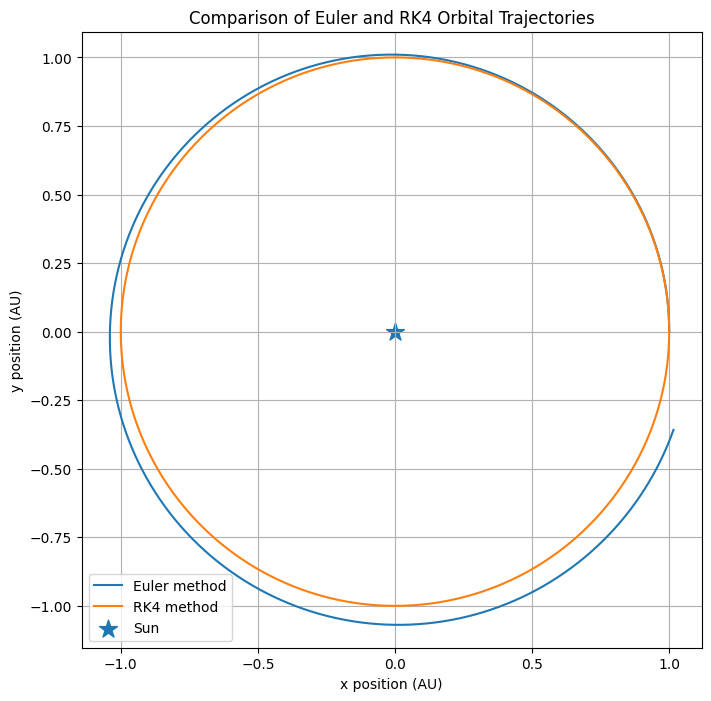

In [144]:
x_euler = states_euler[:, 0]
y_euler = states_euler[:, 1]

x_rk4 = states_rk4[:, 0]
y_rk4 = states_rk4[:, 1]

plt.figure(figsize=(8, 8))

plt.plot(
    x_euler,
    y_euler,
    label="Euler method"
)

plt.plot(
    x_rk4,
    y_rk4,
    label="RK4 method"
)

plt.scatter(
    0,
    0,
    marker="*",
    s=180,
    label="Sun"
)

plt.xlabel("x position (AU)")
plt.ylabel("y position (AU)")
plt.title("Comparison of Euler and RK4 Orbital Trajectories")

plt.axis("equal")
plt.grid()
plt.legend()
plt.show()

The RK4 solution remains very close to the expected circular trajectory throughout the one-year simulation. In contrast, the Euler orbit gradually moves outwards and does not return accurately to its starting position after one orbital period. The outward drift shows that numerical error accumulates in the Euler solution, while RK4 remains close to the expected orbit for the same timestep. 

### 5.2 Radius Conservation

For a perfectly circular orbit, the distance between the planet and the star should remain constant. The orbital radius is calculated at every timestep for both numerical methods using

$$
r = \sqrt{x^2+y^2}.
$$

The maximum change in radius from its initial value is then used as a measure of the numerical error produced by each method.



In [145]:
radius_euler = np.sqrt(
    states_euler[:, 0]**2 + states_euler[:, 1]**2
)

radius_rk4 = np.sqrt(
    states_rk4[:, 0]**2 + states_rk4[:, 1]**2
)

euler_radius_error = np.max(
    np.abs(radius_euler - radius_euler[0])
)

rk4_radius_error = np.max(
    np.abs(radius_rk4 - radius_rk4[0])
)

print("Maximum Euler radius change:", euler_radius_error)
print("Maximum RK4 radius change:", rk4_radius_error)

Maximum Euler radius change: 0.07688873143993269
Maximum RK4 radius change: 4.9560244796964525e-11


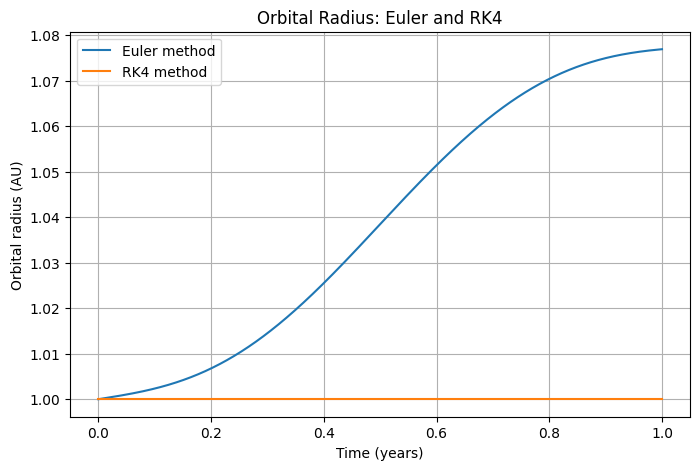

In [146]:
plt.figure(figsize=(8, 5))

plt.plot(
    times_euler,
    radius_euler,
    label="Euler method"
)

plt.plot(
    times_rk4,
    radius_rk4,
    label="RK4 method"
)

plt.xlabel("Time (years)")
plt.ylabel("Orbital radius (AU)")
plt.title("Orbital Radius: Euler and RK4")
plt.grid()
plt.legend()
plt.show()

The Euler method produces a noticeable increase in orbital radius during the simulation, with a maximum deviation of approximately $0.077$ AU from the initial radius. This corresponds to an error of about $7.7\%$ relative to the initial orbital radius of $1$ AU. In contrast, the RK4 method has a maximum deviation of only $5\times10^{-11}$ AU. For the same timestep, its radius error is many orders of magnitude smaller than that of Euler.




### 5.3 Energy Conservation

For the Newtonian gravitational system, the total mechanical energy should remain constant throughout the orbit. Since the mass of the planet is not required for the equations of motion, the specific mechanical energy is used,

$$
\epsilon = \frac{v^2}{2} - \frac{\mu}{r},
$$

where

$$
v^2 = v_x^2 + v_y^2.
$$

Energy conservation gives another way of testing the numerical accuracy of the Euler and RK4 methods. The relative change in specific energy is calculated throughout the one-year simulation for both methods.

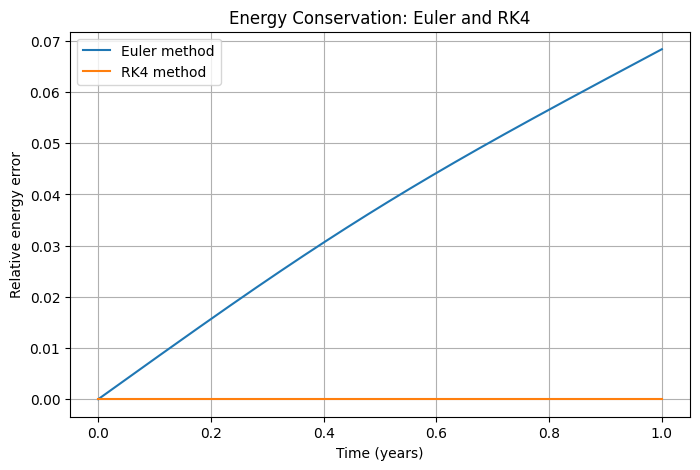

In [147]:
def calculate_specific_energy(states, mu):
    """
    Calculate the specific mechanical energy at each timestep.
    """

    x = states[:, 0]
    y = states[:, 1]
    vx = states[:, 2]
    vy = states[:, 3]

    radius = np.sqrt(x**2 + y**2)
    speed_squared = vx**2 + vy**2

    kinetic_energy = 0.5 * speed_squared
    potential_energy = -mu / radius

    return kinetic_energy + potential_energy

# Calculate the orbital energy for both numerical methods
energy_euler = calculate_specific_energy(states_euler, mu)
energy_rk4 = calculate_specific_energy(states_rk4, mu)

# Calculate the change in energy relative to its initial value
relative_energy_error_euler = (
    (energy_euler - energy_euler[0])
    / np.abs(energy_euler[0])
)

relative_energy_error_rk4 = (
    (energy_rk4 - energy_rk4[0])
    / np.abs(energy_rk4[0])
)


plt.figure(figsize=(8, 5))

plt.plot(
    times_euler,
    relative_energy_error_euler,
    label="Euler method"
)

plt.plot(
    times_rk4,
    relative_energy_error_rk4,
    label="RK4 method"
)

plt.xlabel("Time (years)")
plt.ylabel("Relative energy error")
plt.title("Energy Conservation: Euler and RK4")
plt.grid()
plt.legend()
plt.show()

From the plot above, the Euler method shows a clear increase in relative energy error over the course of the simulation, reaching approximately $6.8\%$ after one year. The increase in energy is consistent with the outward drift seen in the Euler trajectory. 

In comparison, the RK4 solution shows negligible energy variation on the same scale. The much smaller energy variation agrees with the earlier trajectory and radius comparisons.



### 5.4 Timestep Convergence

A numerical integration method should become more accurate as the timestep $\Delta t$ is reduced. To see this, the circular orbit simulation is repeated using a range of timestep values for both the Euler and RK4 methods.

For each timestep, the maximum deviation of the orbital radius from its initial value is used as the error measure,

$$
\mathrm{error}
=
\max \left|r(t)-r(0)\right|.
$$

The errors are then compared on a logarithmic scale. For a numerical method of order $p$, the error is expected to scale approximately as

$$
\mathrm{error} \propto (\Delta t)^p.
$$

The numerical order of each method can be estimated from the slope of a log-log plot of error against timestep.

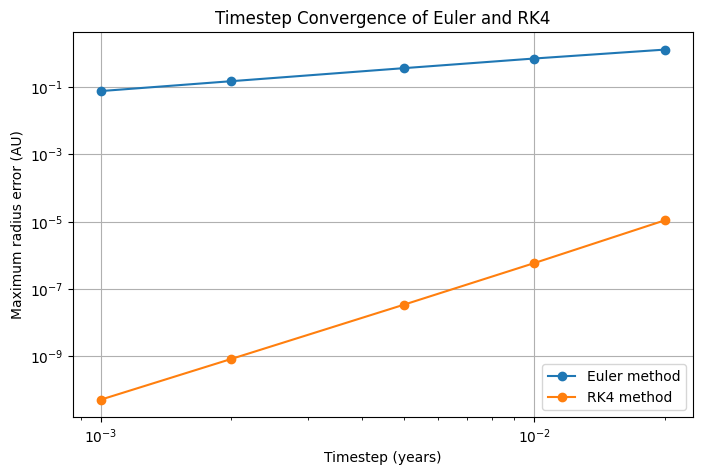

Estimated Euler convergence order: 0.9530661473476447
Estimated RK4 convergence order: 4.097437294865425


In [148]:
dt_values = [0.02, 0.01, 0.005, 0.002, 0.001]

euler_radius_errors = []
rk4_radius_errors = []

# Timestep values used to test numerical convergence
for dt_test in dt_values:

    _, states_euler_test = simulate_orbit_with_method(
        initial_state=initial_state,
        total_time=1.0,
        dt=dt_test,
        mu=mu,
        step_method=euler_step
    )

    _, states_rk4_test = simulate_orbit_with_method(
        initial_state=initial_state,
        total_time=1.0,
        dt=dt_test,
        mu=mu,
        step_method=rk4_step
    )

    radius_euler_test = np.sqrt(
        states_euler_test[:, 0]**2 +
        states_euler_test[:, 1]**2
    )

    radius_rk4_test = np.sqrt(
        states_rk4_test[:, 0]**2 +
        states_rk4_test[:, 1]**2
    )

    euler_error = np.max(
        np.abs(radius_euler_test - radius_euler_test[0])
    )

    rk4_error = np.max(
        np.abs(radius_rk4_test - radius_rk4_test[0])
    )

    # Store the maximum radius error for each method
    euler_radius_errors.append(euler_error)
    rk4_radius_errors.append(rk4_error)


plt.figure(figsize=(8, 5))

plt.loglog(
    dt_values,
    euler_radius_errors,
    marker="o",
    label="Euler method"
)

plt.loglog(
    dt_values,
    rk4_radius_errors,
    marker="o",
    label="RK4 method"
)

plt.xlabel("Timestep (years)")
plt.ylabel("Maximum radius error (AU)")
plt.title("Timestep Convergence of Euler and RK4")
plt.grid()
plt.legend()
plt.show()


euler_order = np.polyfit(
    np.log(dt_values),
    np.log(euler_radius_errors),
    1
)[0]

rk4_order = np.polyfit(
    np.log(dt_values),
    np.log(rk4_radius_errors),
    1
)[0]

print("Estimated Euler convergence order:", euler_order)
print("Estimated RK4 convergence order:", rk4_order)

The numerical error decreases as the timestep is reduced for both methods, but the reduction is much faster for RK4. The estimated convergence orders are approximately $0.95$ for Euler, and $4.10$ for RK4 which is close to the expected fourth-order behaviour. 

Taken together, the trajectory, radius, energy and convergence tests justify using RK4 for the remaining simulations.


## 6. Orbital Trajectories and Eccentricity

### 6.1 Circular, Elliptical, Parabolic and Hyperbolic Orbits
Having established that RK4 provides the more accurate numerical solution, it becomes the chosen method used for the remainder of the investigation. The type of orbit produced depends strongly on the initial velocity of the planet. For a planet beginning at a fixed distance from the star, increasing the tangential velocity changes the orbit from a bound elliptical trajectory to the parabolic escape condition and then to an unbound hyperbolic trajectory [1]. 

The escape velocity at the initial radius is 

$$
v_{\mathrm{escape}} = \sqrt{\frac{2\mu}{r_0}}. 
$$ 

There are four different initial conditions considered: a circular orbit, an elliptical orbit, a parabolic trajectory and a hyperbolic trajectory.

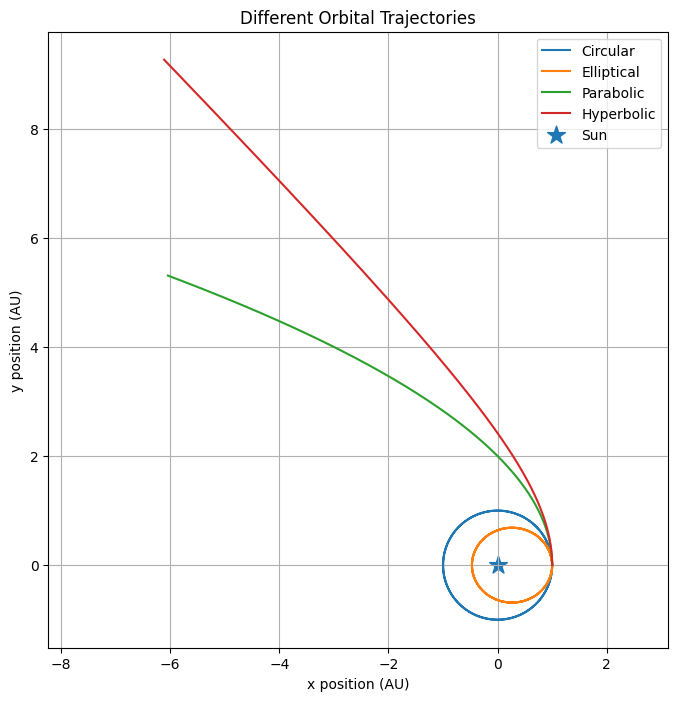

In [149]:
v_escape = np.sqrt(2 * mu / r0)

# Define initial conditions for the four different orbit types
state_circular = np.array(
    [1.0, 0.0, 0.0, v_circular]
)

state_elliptical = np.array(
    [1.0, 0.0, 0.0, 0.8 * v_circular]
)

state_parabolic = np.array(
    [1.0, 0.0, 0.0, v_escape]
)

state_hyperbolic = np.array(
    [1.0, 0.0, 0.0, 1.1 * v_escape]
)

orbit_states = {}

for name, state in {
    "Circular": state_circular,
    "Elliptical": state_elliptical,
    "Parabolic": state_parabolic,
    "Hyperbolic": state_hyperbolic
}.items():

    _, states = simulate_orbit_with_method(
        initial_state=state,
        total_time=2.0,
        dt=0.001,
        mu=mu,
        step_method=rk4_step
    )

    orbit_states[name] = states

plt.figure(figsize=(8, 8))

for name, states in orbit_states.items():

    plt.plot(
        states[:, 0],
        states[:, 1],
        label=name
    )

plt.scatter(
    0,
    0,
    marker="*",
    s=180,
    label="Sun"
)

plt.xlabel("x position (AU)")
plt.ylabel("y position (AU)")
plt.title("Different Orbital Trajectories")
plt.axis("equal")
plt.grid()
plt.legend()
plt.show()

The circular and elliptical trajectories remain bound to the star, while the parabolic and hyperbolic trajectories escape to large distances. The circular orbit is produced when the initial velocity is equal to the circular orbital velocity. Reducing the velocity to $0.8v_{\mathrm{circular}}$ produces an elliptical orbit. At the escape velocity, the trajectory becomes parabolic, while increasing the velocity above the escape velocity produces a hyperbolic orbit. 

 

The orbital trajectories can also be classified quantitatively using their specific orbital energy and eccentricity.

The specific orbital energy is

$$
\epsilon = \frac{v^2}{2} - \frac{\mu}{r},
$$

and the eccentricity is

$$
e = \sqrt{1+\frac{2\epsilon h^2}{\mu^2}},
$$

where the specific angular momentum in two dimensions is

$$
h = xv_y-yv_x.
$$

These quantities distinguish the different orbit types: bound elliptical orbits have $\epsilon<0$ and $e<1$, a parabolic trajectory has $\epsilon=0$ and $e=1$, and a hyperbolic trajectory has $\epsilon>0$ and $e>1$.

In [150]:
def orbital_properties(state, mu):
    """
    Calculate the specific energy, angular momentum and eccentricity
    of an orbital state.
    """
    x, y, vx, vy = state

    r = np.sqrt(x**2 + y**2)
    v_squared = vx**2 + vy**2

    energy = 0.5 * v_squared - mu / r
    h = x * vy - y * vx

    eccentricity = np.sqrt(
        1 + (2 * energy * h**2) / mu**2
    )

    return energy, h, eccentricity


orbit_initial_states = {
    "Circular": state_circular,
    "Elliptical": state_elliptical,
    "Parabolic": state_parabolic,
    "Hyperbolic": state_hyperbolic
}

for name, state in orbit_initial_states.items():

    energy, h, eccentricity = orbital_properties(
        state,
        mu
    )

    print(name)
    print("Specific energy:", energy)
    print("Specific angular momentum:", h)
    print("Eccentricity:", eccentricity)
    print()

Circular
Specific energy: -19.739208802178716
Specific angular momentum: 6.283185307179586
Eccentricity: 0.0

Elliptical
Specific energy: -26.845323970963054
Specific angular momentum: 5.026548245743669
Eccentricity: 0.36000000000000004

Parabolic
Specific energy: 0.0
Specific angular momentum: 8.885765876316732
Eccentricity: 1.0

Hyperbolic
Specific energy: 8.290467696915066
Specific angular momentum: 9.774342463948406
Eccentricity: 1.4200000000000004



The calculated orbital properties agree with the trajectories shown above. The circular orbit has eccentricity $e=0$, while the elliptical case has $e\approx0.36$. Both have negative specific orbital energy and are therefore bound to the star. 

  

The parabolic trajectory has approximately zero specific orbital energy and $e=1$, representing the boundary between bound and unbound motion. The hyperbolic trajectory has positive specific orbital energy and $e>1$, confirming that the planet escapes from the gravitational system becoming unbound from the star. 

### 6.2 Effect of Eccentricity on Bound Orbits

The eccentricity of a bound orbit determines how elongated the ellipse is. A circular orbit has $e=0$, while increasingly elliptical trajectories have larger eccentricities approaching $e=1$.

To investigate this, the initial tangential velocity is reduced by different amounts while keeping the initial position fixed at $1$ AU. Each orbit is simulated using RK4 and its eccentricity is calculated from the initial conditions.

Velocity factor: 1.0 Eccentricity: 0.0
Velocity factor: 0.9 Eccentricity: 0.19000000000000034
Velocity factor: 0.8 Eccentricity: 0.36000000000000004
Velocity factor: 0.7 Eccentricity: 0.51


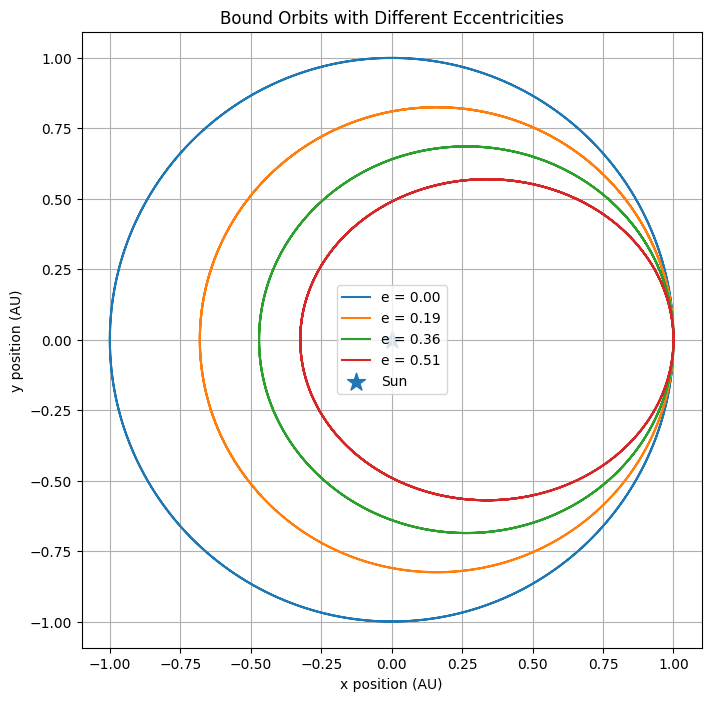

In [151]:
# Initial tangential velocities expressed as fractions of circular velocity
velocity_factors = [1.0, 0.9, 0.8, 0.7]

eccentricity_states = []
eccentricities = []

for factor in velocity_factors:

    state = np.array(
        [1.0, 0.0, 0.0, factor * v_circular]
    )

    _, orbit_states_test = simulate_orbit_with_method(
        initial_state=state,
        total_time=2.0,
        dt=0.001,
        mu=mu,
        step_method=rk4_step
    )

    energy, h, eccentricity = orbital_properties(
        state,
        mu
    )

    eccentricity_states.append(orbit_states_test)
    eccentricities.append(eccentricity)

    print(
        "Velocity factor:",
        factor,
        "Eccentricity:",
        eccentricity
    )


plt.figure(figsize=(8, 8))

for states, eccentricity in zip(
    eccentricity_states,
    eccentricities
):

    plt.plot(
        states[:, 0],
        states[:, 1],
        label=f"e = {eccentricity:.2f}"
    )

plt.scatter(
    0,
    0,
    marker="*",
    s=180,
    label="Sun"
)

plt.xlabel("x position (AU)")
plt.ylabel("y position (AU)")
plt.title("Bound Orbits with Different Eccentricities")
plt.axis("equal")
plt.grid()
plt.legend()
plt.show()

As the initial tangential velocity is reduced below the circular orbital velocity, the eccentricity increases and the orbit becomes more stretched. The circular case has $e=0$, while the remaining bound trajectories have eccentricities of approximately $0.19$, $0.36$ and $0.51$. 

  

The change in eccentricity shows clearly that the orbital shape depends strongly on the initial velocity. All of these trajectories remain bound because their eccentricities satisfy $e<1$ and their specific orbital energies are negative. 

## 7. Modified Gravity and Orbital Precession

The Newtonian gravitational force follows an inverse-square law. In this section the force law is modified slightly in order to investigate how a small departure from the inverse-square dependence affects the orbital trajectory.

The acceleration magnitude is changed from being proportional to $r^{-2}$ to

$$
a \propto r^{-(2+\delta)},
$$

where $\delta$ is a small dimensionless parameter. In the numerical model, distances are measured in AU, so the modified equations of motion can be written as

$$
a_x = -\frac{\mu x}{r^{3+\delta}},
$$

$$
a_y = -\frac{\mu y}{r^{3+\delta}}.
$$

When $\delta=0$, the usual Newtonian inverse-square law is recovered. For non-zero values of $\delta$, the orbit is no longer expected to remain as a closed ellipse, and the orientation of the orbit can gradually change with time.

In [152]:
def modified_equations_of_motion(t, state, mu, delta):
    """
    Return the equations of motion for the modified gravitational force law.
    """
    x, y, vx, vy = state

    r = np.sqrt(x**2 + y**2)

    if r == 0:
        raise ValueError(
            "The planet cannot be located at the centre of the star."
        )

    ax = -mu * x / r**(3 + delta)
    ay = -mu * y / r**(3 + delta)

    return np.array([vx, vy, ax, ay])


def rk4_step_modified(t, state, dt, mu, delta):
    """
    Advance the modified-gravity system by one RK4 timestep.
    """
    k1 = modified_equations_of_motion(
        t, state, mu, delta
    )

    k2 = modified_equations_of_motion(
        t + dt / 2,
        state + dt * k1 / 2,
        mu,
        delta
    )

    k3 = modified_equations_of_motion(
        t + dt / 2,
        state + dt * k2 / 2,
        mu,
        delta
    )

    k4 = modified_equations_of_motion(
        t + dt,
        state + dt * k3,
        mu,
        delta
    )

    return state + (dt / 6) * (
        k1 + 2*k2 + 2*k3 + k4
    )


def simulate_modified_orbit(
    initial_state,
    total_time,
    dt,
    mu,
    delta
):
    """
    Simulate an orbit using the modified gravitational force law.
    """
    number_of_steps = int(total_time / dt)

    times = np.zeros(number_of_steps + 1)
    states = np.zeros(
        (number_of_steps + 1, 4)
    )

    states[0] = initial_state

    for i in range(number_of_steps):

        times[i + 1] = times[i] + dt

        states[i + 1] = rk4_step_modified(
            times[i],
            states[i],
            dt,
            mu,
            delta
        )

    return times, states

The same RK4 integration procedure is used for the modified force law so that the change in orbital behaviour is caused by the force law rather than by changing the numerical integration method.

### 7.2 Comparison with the Newtonian Orbit

To show the effect of the modified force law, an elliptical orbit is simulated for both the Newtonian case, $\delta=0$, and a slightly modified case with $\delta=0.02$. The same initial conditions and numerical method are used in both cases.

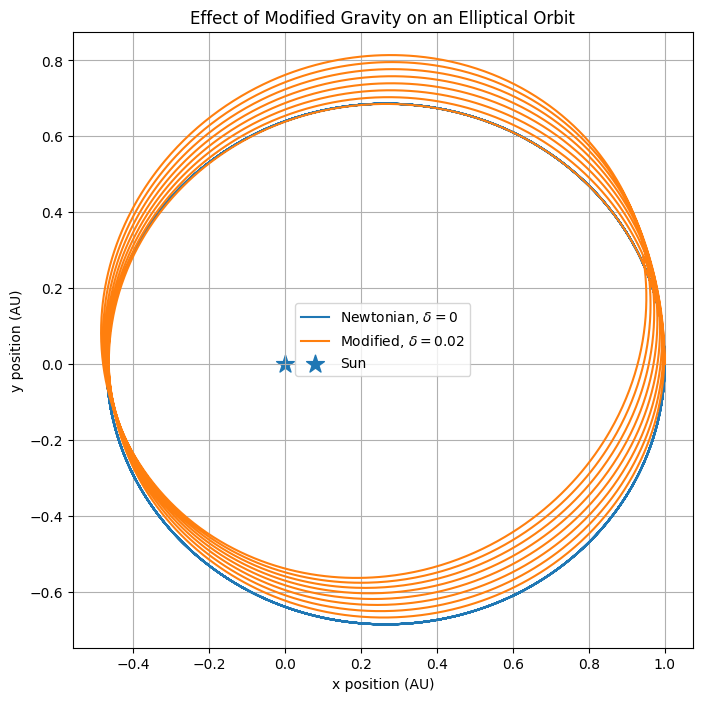

In [153]:
initial_ellipse = np.array(
    [1.0, 0.0, 0.0, 0.8 * v_circular]
)

times_newtonian, states_newtonian = simulate_modified_orbit(
    initial_state=initial_ellipse,
    total_time=5.0,
    dt=0.001,
    mu=mu,
    delta=0.0
)

times_modified, states_modified = simulate_modified_orbit(
    initial_state=initial_ellipse,
    total_time=5.0,
    dt=0.001,
    mu=mu,
    delta=0.02
)

plt.figure(figsize=(8, 8))

plt.plot(
    states_newtonian[:, 0],
    states_newtonian[:, 1],
    label=r"Newtonian, $\delta=0$"
)

plt.plot(
    states_modified[:, 0],
    states_modified[:, 1],
    label=r"Modified, $\delta=0.02$"
)

plt.scatter(
    0,
    0,
    marker="*",
    s=180,
    label="Sun"
)

plt.xlabel("x position (AU)")
plt.ylabel("y position (AU)")
plt.title("Effect of Modified Gravity on an Elliptical Orbit")
plt.axis("equal")
plt.grid()
plt.legend()
plt.show()

For the Newtonian case, the planet repeatedly follows almost the same elliptical path and the orientation of the orbit remains approximately fixed.

For $\delta=0.02$, the orbit does not retrace exactly the same ellipse. Instead, the orientation of the ellipse changes gradually with each orbit, producing a rosette-like trajectory. 

### 7.3 Measuring the Precession

To measure the change in orbital orientation, the periapsis position is identified for each orbit. The periapsis is the point at which the planet is closest to the star.

For each detected periapsis, the angle relative to the positive $x$-axis is calculated using

$$
\theta = \tan^{-1}\left(\frac{y}{x}\right).
$$

In the code, `arctan2` is used so that the correct angle is obtained in all four quadrants. The difference between successive periapsis angles gives the precession per orbit.

In [154]:
def find_periapsis_angles(states):
    x = states[:, 0]
    y = states[:, 1]

    # Calculate the orbital radius at each timestep
    radius = np.sqrt(x**2 + y**2)

    # Identify local minima in radius as periapsis points
    periapsis_indices = np.where(
        (radius[1:-1] < radius[:-2]) &
        (radius[1:-1] < radius[2:])
    )[0] + 1

    # Calculate and unwrap the angle of each periapsis
    angles = np.arctan2(
        y[periapsis_indices],
        x[periapsis_indices]
    )

    angles = np.unwrap(angles)

    return periapsis_indices, angles


indices_newtonian, angles_newtonian = find_periapsis_angles(
    states_newtonian
)

indices_modified, angles_modified = find_periapsis_angles(
    states_modified
)

angles_newtonian_deg = np.degrees(angles_newtonian)
angles_modified_deg = np.degrees(angles_modified)

precession_newtonian = np.diff(angles_newtonian_deg)
precession_modified = np.diff(angles_modified_deg)

print("Newtonian periapsis angles (degrees):")
print(angles_newtonian_deg)

print("\nModified periapsis angles (degrees):")
print(angles_modified_deg)

print("\nMean Newtonian precession per orbit:")
print(np.mean(precession_newtonian), "degrees")

print("\nMean modified precession per orbit:")
print(np.mean(precession_modified), "degrees")

Newtonian periapsis angles (degrees):
[179.66869586 180.3065843  179.64397689 180.2818661  179.61925962
 180.25714953 179.59454405 180.2324346 ]

Modified periapsis angles (degrees):
[-178.68650425 -174.72560855 -170.76471036 -166.80381054 -162.84290994
 -158.88200942 -154.92110983 -150.96021202]

Mean Newtonian precession per orbit:
0.08053410542541428 degrees

Mean modified precession per orbit:
3.9608988891884525 degrees


The periapsis angle for the modified orbit increases from one orbit to the next, giving a mean precession of approximately $3.96^\circ$ per orbit for $\delta=0.02$. For the Newtonian simulation, the measured precession is much smaller, at approximately $0.08^\circ$ per orbit. Ideally this value would be zero, since a Newtonian elliptical orbit should remain closed. The small non-zero result is likely caused by the finite timestep and the way the periapsis position is identified from discrete simulation points. The $3.96^\circ$ shift for $\delta=0.02$ is much larger than this residual numerical effect.

### 7.4 Dependence of Precession on $\delta$

To investigate how the amount of precession depends on the modification to the force law, the simulation is repeated for several values of $\delta$.

For each value, the periapsis angles are identified and the mean change in angle between successive periapsis positions is calculated. The values considered are

$$
\delta = 0,\ 0.005,\ 0.010,\ 0.015,\ 0.020.
$$

This allows the relationship between the strength of the modification and the resulting orbital precession to be examined.

delta = 0.0 mean precession = 0.08053410542541428 degrees per orbit
delta = 0.005 mean precession = 1.0803540845477275 degrees per orbit
delta = 0.01 mean precession = 1.9038210172325267 degrees per orbit
delta = 0.015 mean precession = 2.926239127480918 degrees per orbit
delta = 0.02 mean precession = 3.9608988891884525 degrees per orbit


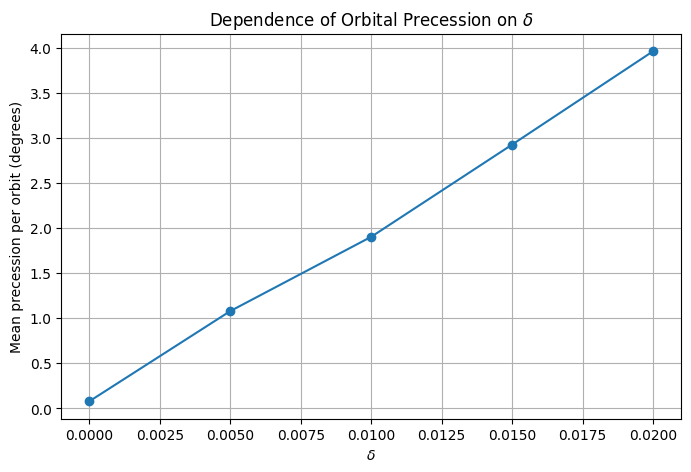

In [155]:
delta_values = [0.0, 0.005, 0.01, 0.015, 0.02]

mean_precessions = []

for delta_test in delta_values:

    _, states_delta = simulate_modified_orbit(
        initial_state=initial_ellipse,
        total_time=5.0,
        dt=0.001,
        mu=mu,
        delta=delta_test
    )

    _, angles_delta = find_periapsis_angles(
        states_delta
    )

    angles_delta_deg = np.degrees(
        angles_delta
    )

    precession_delta = np.diff(
        angles_delta_deg
    )

    mean_precession = np.mean(
        precession_delta
    )

    mean_precessions.append(
        mean_precession
    )

    print(
        "delta =",
        delta_test,
        "mean precession =",
        mean_precession,
        "degrees per orbit"
    )


plt.figure(figsize=(8, 5))

plt.plot(
    delta_values,
    mean_precessions,
    marker="o"
)

plt.xlabel(r"$\delta$")
plt.ylabel("Mean precession per orbit (degrees)")
plt.title("Dependence of Orbital Precession on $\delta$")
plt.grid()
plt.show()

The measured precession increases steadily as $\delta$ is increased. For $\delta=0.005$, the mean precession is approximately $1.08^\circ$ per orbit, while for $\delta=0.02$ it rises to approximately $3.96^\circ$ per orbit.

Over the range tested, the relationship between $\delta$ and the precession appears close to linear. The Newtonian case, $\delta=0$, gives a much smaller value of about $0.08^\circ$ per orbit. This residual value is likely due to the finite timestep and the fact that the periapsis is identified from discrete points in the numerical solution.


### 7.5 Numerical Check of the Precession Measurement

The small non-zero precession measured for the Newtonian case should ideally disappear as the timestep is reduced. To check whether this residual value is caused by numerical resolution, the Newtonian simulation is repeated using several smaller timestep values.

If the measured precession moves closer to zero as $\Delta t$ decreases, this provides evidence that the remaining Newtonian precession is a numerical effect rather than a physical one.

In [156]:
dt_precession_values = [0.002, 0.001, 0.0005]

newtonian_precession_results = []

for dt_test in dt_precession_values:

    _, states_test = simulate_modified_orbit(
        initial_state=initial_ellipse,
        total_time=5.0,
        dt=dt_test,
        mu=mu,
        delta=0.0
    )

    _, angles_test = find_periapsis_angles(
        states_test
    )

    angles_test_deg = np.degrees(
        angles_test
    )

    precession_test = np.diff(
        angles_test_deg
    )

    mean_precession_test = np.mean(
        precession_test
    )

    newtonian_precession_results.append(
        mean_precession_test
    )

    print(
        "dt =",
        dt_test,
        "Newtonian precession =",
        mean_precession_test,
        "degrees per orbit"
    )

dt = 0.002 Newtonian precession = -0.2909776571679125 degrees per orbit
dt = 0.001 Newtonian precession = 0.08053410542541428 degrees per orbit
dt = 0.0005 Newtonian precession = -0.012360085126918616 degrees per orbit


As the timestep is reduced, the magnitude of the measured Newtonian precession becomes much smaller. At $\Delta t=0.0005$ years, the measured value is only about $0.012^\circ$ per orbit in magnitude, compared with approximately $0.29^\circ$ for $\Delta t=0.002$ years.

The sign of the small residual value changes between simulations because the exact periapsis does not necessarily occur at one of the discrete simulation points. The important feature is that its magnitude moves closer to zero as the timestep is reduced.

This supports the interpretation that the small precession measured for $\delta=0$ is caused by the numerical resolution of the periapsis position. By comparison, the modified case reaches $3.96^\circ$ per orbit for $\delta=0.02$.

## 8. Discussion

The difference between the two integration methods was large. Euler could produce an orbit, but its accuracy deteriorated as the simulation went on: after one year the orbital radius had drifted by about 0.077 AU, and the relative energy error had climbed to roughly 6.8%. The outward drift in the trajectory plot is consistent with this same numerical error appearing geometrically.

RK4 did much better with an identical timestep, giving a radius change of only around $5\times10^{-11}$ AU, with no visible energy drift at all on the scale used here. The convergence test backs this up. The estimated order was 0.95 for Euler and 4.10 for RK4, close to the theoretical first- and fourth-order behaviour. RK4 was used for everything afterwards for this reason.

Varying the initial velocity reproduced the orbit types theory predicts: circular at the exact circular velocity, elliptical below it, the escape-velocity boundary giving a parabolic trajectory, and hyperbolic beyond that. The eccentricity and energy values matched what the plots showed in each case, and reducing the initial velocity further simply stretched the ellipse into higher eccentricities.

The modified force law gave the clearest result in the whole project. At $\delta=0$, the orbit barely changed from one orbit to the next. At $\delta=0.02$, it visibly rotated, producing a precession of about $3.96^\circ$ per orbit, and increasing $\delta$ increased the precession in what looks like a roughly linear relationship over the range tested.

The model has real limitations. The star is fixed and treated as much more massive than the planet, so stellar motion and the gravitational effects of other planets are both ignored, and the model is restricted to two dimensions. There is also a measurement issue: periapsis is detected at discrete timesteps, so the true closest point can fall between two of them. This shows up directly in the Newtonian case, where the orbit should be perfectly closed but a small non-zero precession was measured anyway. Reducing the timestep from 0.002 to 0.0005 years shrank this artefact from about $0.29^\circ$ down to $0.012^\circ$ per orbit, providing good evidence that it is numerical rather than physical.

A few extensions would be worth trying. A finer timestep or a better periapsis-detection method would tighten up the precession measurement. It would also be worth comparing RK4 against symplectic methods like leapfrog or Verlet, especially over much longer integration times. Finally, letting the star move, or adding a second planet, would open the model up to more realistic two- and three-body dynamics.

## 9. Conclusion

This project investigated the numerical simulation of planetary orbits using the Euler and fourth-order Runge-Kutta methods. The comparison showed that RK4 was far more accurate for the same timestep, with much smaller changes in orbital radius and energy. The convergence test also gave results close to the expected first-order behaviour for Euler and fourth-order behaviour for RK4.

Using RK4, different initial velocities were shown to produce circular, elliptical, parabolic and hyperbolic trajectories. The calculated orbital energy and eccentricity values agreed with these classifications, and reducing the initial tangential velocity produced increasingly eccentric bound orbits.

The modified force-law simulations showed that changing the radial dependence from the Newtonian inverse-square form can lead to orbital precession. For $\delta=0.02$, the measured precession was approximately $3.96^\circ$ per orbit, and the amount of precession increased as $\delta$ was increased. A timestep check also showed that the small non-zero precession in the Newtonian case decreases as the numerical resolution is improved.

Overall, the project shows both the importance of choosing an appropriate numerical integration method and how numerical simulations can be used to investigate the physical behaviour of orbital systems. Further work could include using other integration methods, improving the periapsis measurement, or extending the model to include multiple moving bodies.

## References
[1] J. R. Taylor, *Classical Mechanics* (University Science Books, 2005).

[2] W. H. Press, S. A. Teukolsky, W. T. Vetterling and B. P. Flannery, *Numerical Recipes: The Art of Scientific Computing*, 3rd ed. (Cambridge University Press, 2007).

[3] E. Hairer, S. P. Nørsett and G. Wanner, *Solving Ordinary Differential Equations I: Nonstiff Problems*, 2nd ed. (Springer, 1993).


# Appendix A: Generative AI Use

Generative AI (ChatGPT) was used as a support tool during the development of this project. It was mainly used to clarify concepts, provide suggestions during parts of the Python implementation and debugging process, suggest possible numerical tests, and provide feedback on the organisation and wording of the report.

The final numerical model was implemented and run in the submitted Jupyter Notebook. The simulations, plots and numerical values presented in the report were produced from the code contained in the notebook. The numerical results were checked against the expected physical behaviour of the system, and additional tests were carried out where numerical effects required further investigation.

ChatGPT outputs were not treated as academic sources. The physical and numerical concepts used in the final report were checked against the academic references listed in the References section. ChatGPT was therefore used to support the development process rather than as a replacement for the numerical investigation and evaluation carried out in the project.

The sections below provide a summary of where ChatGPT assistance was used.

## A.1 Project Scope and Planning

ChatGPT was used during the early stages of the project to discuss possible ways of approaching the planetary-orbits topic and to help organise the investigation into a manageable structure.

Following this discussion, the project was developed around a two-dimensional model of a single planet orbiting a fixed central star. The investigation was structured to compare two numerical integration methods, test their numerical accuracy, investigate the effect of changing the initial orbital velocity, and finally examine precession produced by a modified gravitational force law.

The decision to focus on the single-planet model rather than extending the project to a three-body system allowed the numerical behaviour of the simpler system to be investigated in greater detail.

## A.2 Physical and Mathematical Background

ChatGPT was used to help clarify some of the physical and mathematical relationships required for the simulation, including the conversion of the gravitational equations of motion into a system of first-order differential equations.

The model itself was based on Newtonian gravity, with the star fixed at the origin and the planet treated as having negligible mass in comparison. The state of the system was represented by the planet's position and velocity components,

$$
\mathbf{S}=[x,y,v_x,v_y].
$$

The relationships used for circular velocity, specific orbital energy, angular momentum and eccentricity were included in the report and checked against the academic sources listed in the References section.

ChatGPT was used mainly as an explanatory aid when organising this background material.

## A.3 Numerical Integration Methods

ChatGPT was consulted while implementing and checking the Euler and fourth-order Runge-Kutta methods.

The Euler implementation used in the notebook was:

```python
def euler_step(function, t, state, dt, mu):
    derivatives = function(t, state, mu)
    new_state = state + dt * derivatives
    return new_state
```

The RK4 implementation was:

```python
def rk4_step(function, t, state, dt, mu):
    k1 = function(t, state, mu)
    k2 = function(t + dt / 2, state + dt * k1 / 2, mu)
    k3 = function(t + dt / 2, state + dt * k2 / 2, mu)
    k4 = function(t + dt, state + dt * k3, mu)

    new_state = state + (dt / 6) * (
        k1 + 2*k2 + 2*k3 + k4
    )

    return new_state
```

ChatGPT provided assistance with the structure of these routines and with explaining how they applied to the orbital equations. The methods were then incorporated into the simulation code in the notebook and tested using the numerical experiments described in the report.

## A.4 Initial Conditions and Orbit Simulation

ChatGPT was used to discuss suitable initial conditions for testing the simulation.

The planet was initially placed at a distance of $1$ AU from the star and given a tangential velocity. For the initial validation case, the velocity was chosen to correspond to a circular orbit.

The simulation code was then used to repeatedly advance the state of the planet and store the position and velocity at each timestep. A timestep of $0.001$ years was used for the main numerical experiments.

The resulting trajectories and numerical outputs were produced by running the notebook.

## A.5 Comparison of Euler and RK4

ChatGPT was used to suggest possible ways of comparing the performance of the Euler and RK4 methods. Rather than comparing the trajectories visually alone, the final investigation examined the orbital radius, specific mechanical energy and timestep convergence.

These tests were implemented and run in the notebook.

For a one-year circular-orbit simulation with $\Delta t=0.001$ years, the numerical results showed that the Euler solution produced a maximum radius change of approximately $0.077$ AU, while the corresponding RK4 change was approximately $5\times10^{-11}$ AU.

The Euler solution also developed a relative energy error of approximately $6.8\%$, whereas the RK4 energy variation was negligible on the scale used in the comparison.

These values were obtained directly from the simulations rather than from ChatGPT.

## A.6 Timestep Convergence

ChatGPT was used to discuss how the numerical convergence of the two methods could be tested.

The final convergence test repeated the circular-orbit simulation using

```python
dt_values = [0.02, 0.01, 0.005, 0.002, 0.001]
```

and measured the maximum change in orbital radius for each timestep.

The numerical order was then estimated from the dependence of the error on timestep. The notebook produced convergence orders of approximately $0.95$ for Euler and $4.10$ for RK4.

These results were compared with the expected first-order and fourth-order behaviour described in the numerical-method references used in the report. This provided an independent numerical check that the two integration methods were behaving as expected.

## A.7 Orbital Classification and Eccentricity

ChatGPT was used as a support tool while extending the simulation to different initial velocities and while checking the equations used to calculate orbital energy and eccentricity.

The final simulations used different tangential velocities to produce circular, elliptical, parabolic and hyperbolic trajectories.

The calculated eccentricities were approximately

- $e=0$ for the circular case,
- $e=0.36$ for the elliptical case,
- $e=1$ for the parabolic case, and
- $e=1.42$ for the hyperbolic case.

The orbital energies and trajectories obtained from the simulation were then used to check that these classifications were consistent with the theoretical expectations.

A further set of bound orbits was generated using initial velocities equal to $1.0$, $0.9$, $0.8$ and $0.7$ times the circular velocity. The calculated eccentricities increased from $0$ to approximately $0.51$ as the initial tangential velocity was reduced.

The numerical calculations and plots were produced by running the code in the notebook.

## A.8 Modified Gravitational Force Law

ChatGPT was consulted during the implementation of the modified gravitational force law used in the final part of the project.

The radial dependence of the gravitational acceleration was changed from the Newtonian inverse-square form to

$$
a\propto r^{-(2+\delta)}.
$$

The corresponding acceleration components were implemented in the notebook as

$$
a_x=-\frac{\mu x}{r^{3+\delta}},
\qquad
a_y=-\frac{\mu y}{r^{3+\delta}}.
$$

The existing RK4 method was then adapted to include the additional parameter $\delta$.

The resulting simulations were run for both the Newtonian case, $\delta=0$, and a modified case with $\delta=0.02$. The modified simulation produced a gradual change in the orientation of the elliptical orbit, which motivated the quantitative precession measurement that followed.

## A.9 Measurement of Apsidal Precession

ChatGPT was used to discuss possible methods for measuring the precession numerically.

The final method implemented in the notebook calculated the orbital radius at each timestep and identified local minima as periapsis points. The angular position of each periapsis was then calculated using `arctan2`, and the change in angle between successive periapsis points was used to estimate the apsidal precession.

The notebook measured a mean precession of approximately $3.96^\circ$ per orbit for $\delta=0.02$.

A small non-zero value of approximately $0.08^\circ$ per orbit was initially obtained for the Newtonian case. Rather than assuming that this represented a physical effect, an additional timestep test was carried out.

Reducing the timestep from $0.002$ to $0.0005$ years reduced the magnitude of the measured Newtonian precession from approximately $0.29^\circ$ to $0.012^\circ$ per orbit. This supported the interpretation that the residual Newtonian value resulted from the finite numerical resolution and the discrete method used to locate periapsis.

This additional numerical test and its interpretation formed part of the evaluation of the final simulation.

## A.10 Report Development and Verification

ChatGPT was also used to provide feedback during preparation of the written report. This included suggestions on report organisation, clarity of explanations, Markdown and LaTeX formatting, code comments, possible limitations of the model and areas where academic references were required.

The final report was reviewed alongside the numerical outputs produced by the notebook. The principal numerical conclusions were based on results generated from the simulations, including the comparison of Euler and RK4, the timestep-convergence analysis, the classification of the different orbital trajectories and the precession measurements.
